<a href="https://colab.research.google.com/github/Mangbunn/nets7052_fa26/blob/main/Broadus_Comp_Meths_HW3_GraphTool.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Q1:

**(a)** Replicate Fig. 2 of Guimerà, Sales-Pardo & Amaral (2004)

In [ ]:
%%bash
set -e
CODENAME=$(lsb_release -cs)
echo "deb [arch=amd64] https://downloads.skewed.de/apt $CODENAME main" > /etc/apt/sources.list.d/graph-tool.list
apt-key adv --keyserver keyserver.ubuntu.com --recv-key 612DEFB798507F25 || true
apt-get update -qq
apt-get install -y -qq python3-graph-tool python3-cairo python3-matplotlib > /dev/null

Executing: /tmp/apt-key-gpghome.cQChnA4Pw4/gpg.1.sh --keyserver keyserver.ubuntu.com --recv-key 612DEFB798507F25


gpg: key 612DEFB798507F25: "Tiago de Paula Peixoto <tiago@skewed.de>" not changed
gpg: Total number processed: 1
gpg:              unchanged: 1
W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
W: https://downloads.skewed.de/apt/dists/noble/InRelease: Key is stored in legacy trusted.gpg keyring (/etc/apt/trusted.gpg), see the DEPRECATION section in apt-key(8) for details.


In [ ]:
!pip install -q condacolab
import condacolab; condacolab.install()   # runtime restarts
# after restart:
!mamba install -q -y -c conda-forge graph-tool


📢 Announcement 📢
condacolab==0.2 will be released soon! Try it with:

    !pip install -q https://github.com/conda-incubator/condacolab/archive/main.zip
    import condacolab
    condacolab.install()

0.2.x introduces a new installation method based on Pixi, with customizable Python versions.
This may be breaking for your workflow. If that's the case, please report it at
https://github.com/conda-incubator/condacolab and pin your `pip install` command to:

    !pip install -q 'condacolab==0.1.*'

✨🍰✨ Everything looks OK!


In [ ]:
import sys
sys.path.append("/usr/lib/python3/dist-packages")   # so Colab's python finds the apt-installed graph-tool

import numpy as np
import networkx as nx
import numba as nb
import matplotlib.pyplot as plt
import graph_tool.all as gt

print("graph-tool", gt.__version__)

graph-tool 3.9


Q1 A

In [ ]:
@nb.njit
def modularity_sa(indptr, indices, n_sweeps, T0, T1, seed):
    """Perform Simulated Annealing (SA) optimization to maximize network modularity.

    This function searches for a community partition of a network that maximizes its
    modularity score. It utilizes a geometric cooling schedule and a stochastic transition
    rule (metropolis criterion) to accept changes that lower modularity with a certain
    probability, allowing the algorithm to escape local maxima.

    Parameters
    ----------
    indptr : numpy.ndarray of int64
        The index pointers of the CSR representation of the graph's adjacency matrix.
    indices : numpy.ndarray of int64
        The column indices of the CSR representation of the graph's adjacency matrix.
    n_sweeps : int
        The number of temperature cooling steps to perform.
    T0 : float
        The initial temperature. Higher values allow broader random exploration.
    T1 : float
        The final temperature. Values close to zero restrict the search to greedy hill-climbing.
    seed : int
        The seed for the random number generator to ensure reproducibility.

    Returns
    -------
    tuple
        best_Q : float
            The highest modularity score found during the simulated annealing run.
        best_b : numpy.ndarray of int64
            The community assignments for each node corresponding to the highest modularity score.
    """
    np.random.seed(seed)
    N = len(indptr) - 1
    k = np.zeros(N)
    for i in range(N):
        k[i] = indptr[i + 1] - indptr[i]
    L = k.sum() / 2.0

    b = np.arange(N)            # start with every node in its own group
    d = k.copy()                # total degree of each group
    Q = 0.0
    for s in range(N):
        Q -= (d[s] / (2 * L)) ** 2
    best_Q, best_b = Q, b.copy()

    for sweep in range(n_sweeps):
        T = T0 * (T1 / T0) ** (sweep / max(n_sweeps - 1, 1))   # geometric cooling
        for _ in range(N):
            i = np.random.randint(N)
            a = b[i]
            u = np.random.random()
            if u < 0.8 and k[i] > 0:                           # join a random neighbor's group
                c = b[indices[indptr[i] + np.random.randint(int(k[i]))]]
            elif u < 0.9:                                      # join a random node's group
                c = b[np.random.randint(N)]
            else:                                              # jump to a (likely empty) group label
                c = np.random.randint(N)
            if c == a:
                continue
            kia, kic = 0.0, 0.0
            for p in range(indptr[i], indptr[i + 1]):
                bj = b[indices[p]]
                if bj == a:
                    kia += 1
                elif bj == c:
                    kic += 1
            dQ = (kic - kia) / L - k[i] * (d[c] - d[a] + k[i]) / (2 * L * L)
            if dQ >= 0 or np.random.random() < np.exp(dQ / T):
                b[i] = c
                d[a] -= k[i]
                d[c] += k[i]
                Q += dQ
                if Q > best_Q + 1e-12:
                    best_Q, best_b = Q, b.copy()
    return best_Q, best_b


def max_modularity(G, n_sweeps=1500, T0=0.02, T1=1e-5, n_restarts=3, seed=0):
    """Find the optimal community modularity score across multiple simulated annealing runs.

    This function converts a NetworkX graph into a CSR matrix representation and executes
    independent simulated annealing optimizations (`modularity_sa`) across multiple runs
    with different random seeds to avoid getting trapped in sub-optimal local extrema.

    Parameters
    ----------
    G : networkx.Graph
        The NetworkX graph for which the community structure and modularity are to be evaluated.
    n_sweeps : int, optional
        The number of annealing sweeps per run. Default is 1500.
    T0 : float, optional
        The starting temperature for the annealing cooling schedule. Default is 0.02.
    T1 : float, optional
        The ending temperature for the annealing cooling schedule. Default is 1e-5.
    n_restarts : int, optional
        The number of independent restarts to run with varying seeds. Default is 3.
    seed : int, optional
        The base seed used to generate sequence seeds for each independent run. Default is 0.

    Returns
    -------
    float
        The maximum modularity score found across all independent simulated annealing restarts.
    """
    A = nx.to_scipy_sparse_array(G, format="csr")
    indptr, indices = A.indptr.astype(np.int64), A.indices.astype(np.int64)
    return max(modularity_sa(indptr, indices, n_sweeps, T0, T1, seed + r)[0]
               for r in range(n_restarts))

In [ ]:
sizes = [50, 100, 150, 200, 250, 300]
ms = [1, 2, 3, 4, 5]
n_real = 10                      # network realizations per (S, m); error bars = std dev

results = {}                     # (m, S) -> (mean, std)
for m in ms:
    for S in sizes:
        qs = [max_modularity(nx.barabasi_albert_graph(S, m, seed=1000 * m + 10 * S + r), seed=r)
              for r in range(n_real)]
        results[(m, S)] = (np.mean(qs), np.std(qs))
    #print(f"m={m} done")

m=1 done
m=2 done
m=3 done
m=4 done
m=5 done


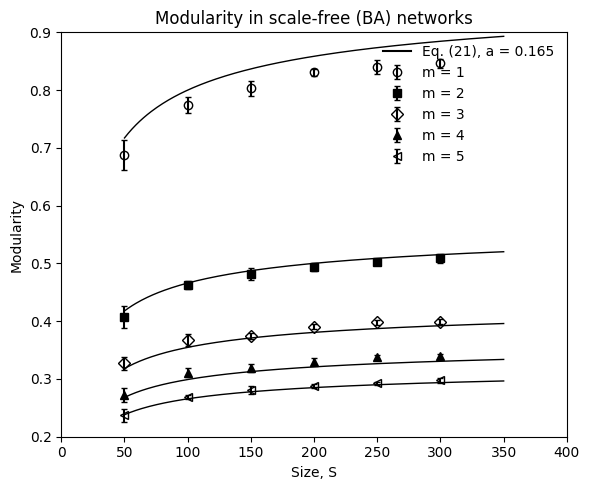

    S    m=1:mean±std    m=2:mean±std    m=3:mean±std    m=4:mean±std    m=5:mean±std
   50     0.688±0.026     0.408±0.019     0.327±0.012     0.272±0.012     0.237±0.011
  100     0.774±0.014     0.462±0.007     0.368±0.011     0.311±0.007     0.268±0.003
  150     0.803±0.013     0.482±0.010     0.375±0.005     0.319±0.007     0.281±0.007
  200     0.831±0.006     0.493±0.007     0.391±0.004     0.330±0.006     0.288±0.004
  250     0.840±0.012     0.502±0.005     0.398±0.005     0.337±0.004     0.293±0.003
  300     0.846±0.008     0.509±0.008     0.399±0.005     0.340±0.003     0.297±0.004
fitted a (m>=2) = 0.172    (paper: 0.165 ± 0.009)


In [ ]:
def M_SF(S, m, a=0.165):
    return (a + (1 - a) / m) * (1 - 2 / np.sqrt(S))

markers = {1: ("o", "none"), 2: ("s", "k"), 3: ("D", "none"), 4: ("^", "k"), 5: ("<", "none")}
S_line = np.linspace(50, 350, 200)

fig, ax = plt.subplots(figsize=(6, 5))
for m in ms:
    mk, fc = markers[m]
    mean = [results[(m, S)][0] for S in sizes]
    std = [results[(m, S)][1] for S in sizes]
    ax.errorbar(sizes, mean, yerr=std, fmt=mk, mfc=fc, mec="k", ecolor="k", color="k",
                ms=6, capsize=2, label=f"m = {m}")
    ax.plot(S_line, M_SF(S_line, m), "k-", lw=1)
ax.plot([], [], "k-", label="Eq. (21), a = 0.165")
ax.set_xlim(0, 400); ax.set_ylim(0.2, 0.9)
ax.set_xlabel("Size, S"); ax.set_ylabel("Modularity")
ax.legend(frameon=False)
ax.set_title("Modularity in scale-free (BA) networks")
plt.tight_layout(); plt.show()

# numerical table + fit of 'a' (modularity is linear in 1/m at fixed S, Eq. 21)
print(f"{'S':>5} " + " ".join(f"m={m}:mean±std".rjust(15) for m in ms))
for S in sizes:
    print(f"{S:>5} " + " ".join(f"{results[(m,S)][0]:.3f}±{results[(m,S)][1]:.3f}".rjust(15) for m in ms))

# least-squares estimate of a:  M / (1 - 2/sqrt(S)) = a + (1-a)/m = a(1 - 1/m) + 1/m
num, den = 0.0, 0.0
for (m, S), (mu, _) in results.items():
    y = mu / (1 - 2 / np.sqrt(S)) - 1 / m
    x = 1 - 1 / m
    num += x * y; den += x * x
print("fitted a (m>=2) =", round(num / den, 3), "   (paper: 0.165 ± 0.009)")

## (b) Two-block SBM vs. degree-corrected SBM on `polblogs`


In [ ]:
g = gt.collection.ns["polblogs"]
print(g)

# largest connected component (weak connectivity, i.e. ignoring edge direction)
g = gt.extract_largest_component(g, directed=False, prune=True)
print(f"LCC: {g.num_vertices()} nodes, {g.num_edges()} edges, directed={g.is_directed()}")
print("vertex properties:", list(g.vp.keys()))

<Graph object, directed, with 1490 vertices and 19090 edges, 4 internal vertex properties, 6 internal graph properties, at 0x7f287d46d400>
LCC: 1222 nodes, 19089 edges, directed=True
vertex properties: ['label', 'source', 'value', '_pos']


In [ ]:
def fit_two_blocks(g, deg_corr, n_trials=10, seed=42):
    """Best (lowest description length) 2-block SBM over several independent runs."""
    gt.seed_rng(seed); np.random.seed(seed)
    best = None
    for _ in range(n_trials):
        state = gt.minimize_blockmodel_dl(
            g,
            state_args=dict(deg_corr=deg_corr),
            multilevel_mcmc_args=dict(B_min=2, B_max=2),   # force exactly 2 blocks
        )
        if best is None or state.entropy() < best.entropy():
            best = state
    return best

state_sbm = fit_two_blocks(g, deg_corr=False)
state_dc  = fit_two_blocks(g, deg_corr=True)

for name, st in [("SBM (non-DC)", state_sbm), ("DC-SBM", state_dc)]:
    b = st.get_blocks().a.copy()                 # numpy array of block labels
    labels, sizes = np.unique(b, return_counts=True)
    print(f"{name:13s}  B = {len(labels)}  block sizes = {sizes}  "
          f"description length = {st.entropy():.1f} nats")

SBM (non-DC)   B = 2  block sizes = [894 328]  description length = 83086.9 nats
DC-SBM         B = 2  block sizes = [670 552]  description length = 63430.3 nats


In [ ]:
# Compare to the labels in the dataset (political leaning), if present
truth = g.vp["value"] if "value" in g.vp else None
if truth is not None:
    for name, st in [("SBM (non-DC)", state_sbm), ("DC-SBM", state_dc)]:
        b = st.get_blocks()
        print(f"{name:13s} NMI with political leaning = {gt.mutual_information(b, truth, norm=True):.3f}   "
              f"overlap = {gt.partition_overlap(b, truth):.3f}")

SBM (non-DC)  NMI with political leaning = 0.000   overlap = 0.514
DC-SBM        NMI with political leaning = 0.706   overlap = 0.946


Non-degree-corrected SBM (B=2)


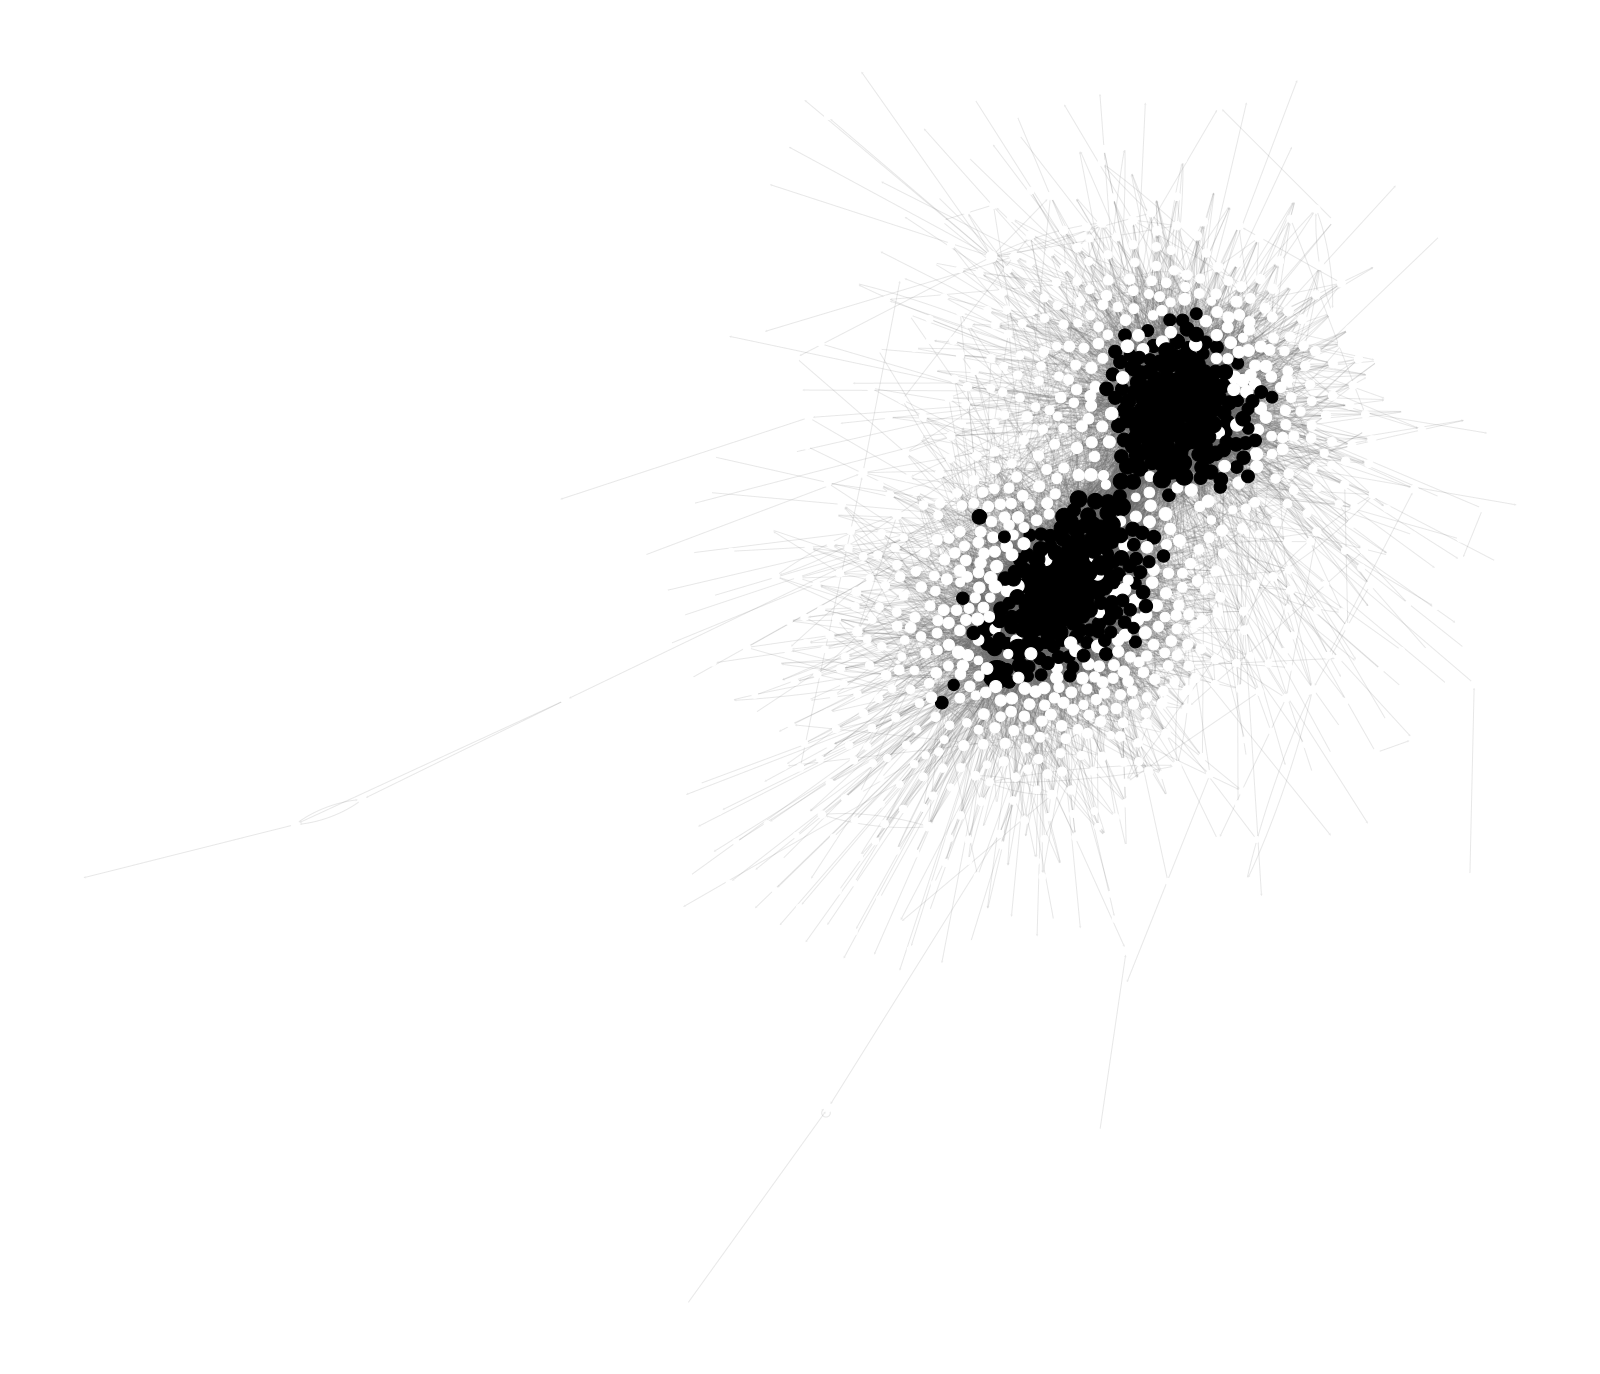

Degree-corrected SBM (B=2)


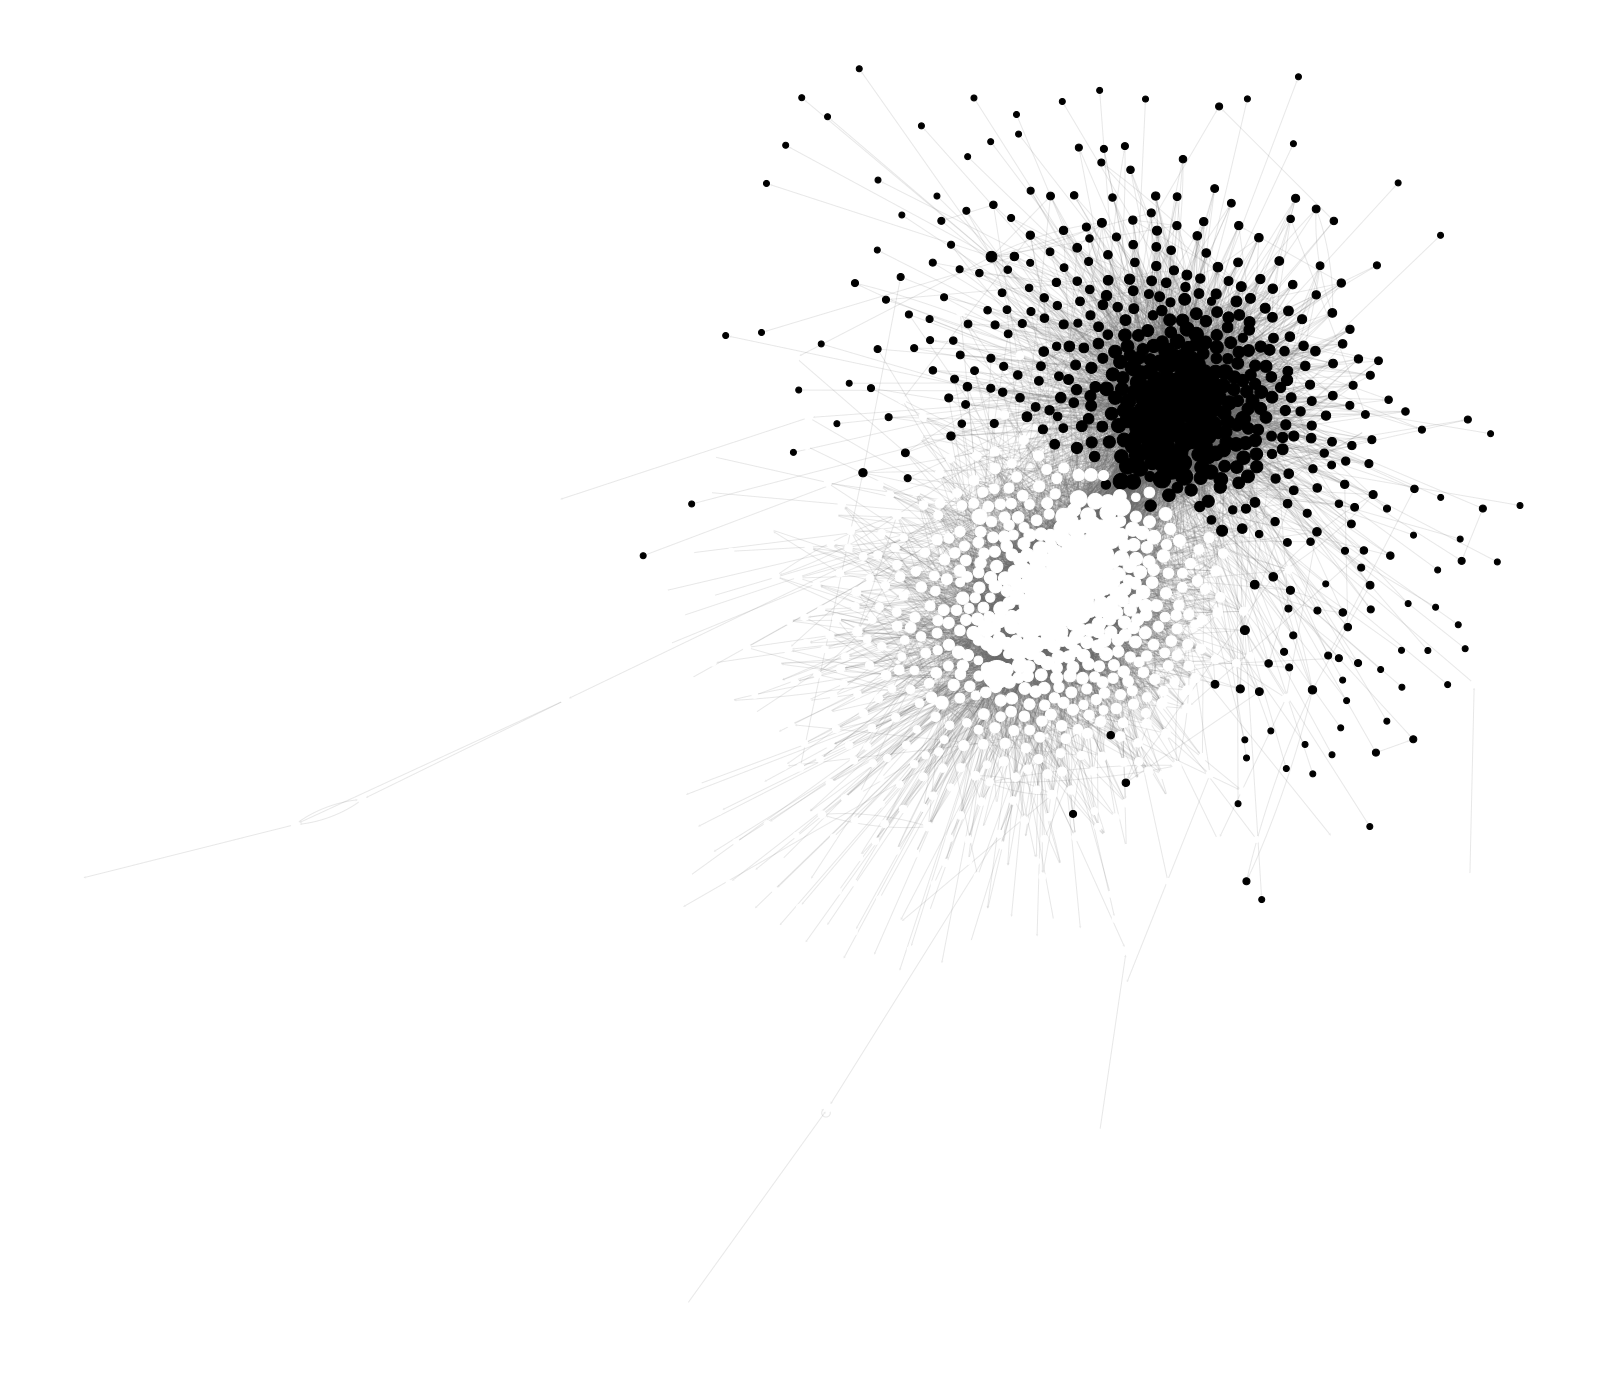

In [ ]:
from IPython.display import Image, display

# same layout for both drawings so that only the partition changes
pos = gt.sfdp_layout(g)
deg = g.degree_property_map("total")
vsize = gt.prop_to_size(deg, mi=3, ma=14, power=0.5)

for name, st, fn in [("Non-degree-corrected SBM (B=2)", state_sbm, "polblogs_sbm.png"),
                     ("Degree-corrected SBM (B=2)",     state_dc,  "polblogs_dcsbm.png")]:
    b = st.get_blocks()
    gt.graph_draw(g, pos=pos, vertex_fill_color=b, vertex_color=b, vertex_size=vsize,
                  edge_color=[0.4, 0.4, 0.4, 0.15], edge_pen_width=0.5,
                  output_size=(800, 800), output=fn)
    print(name)
    display(Image(fn))

## (C) Description lengths

In [ ]:
print(f"Non-degree-corrected SBM (B=2): description length = {state_sbm.entropy():.1f} nats")
print(f"Degree-corrected SBM     (B=2): description length = {state_dc.entropy():.1f} nats")
print(f"Difference (SBM - DC-SBM):      {state_sbm.entropy() - state_dc.entropy():.1f} nats")

Non-degree-corrected SBM (B=2): description length = 83086.9 nats
Degree-corrected SBM     (B=2): description length = 63430.3 nats
Difference (SBM - DC-SBM):      19656.6 nats


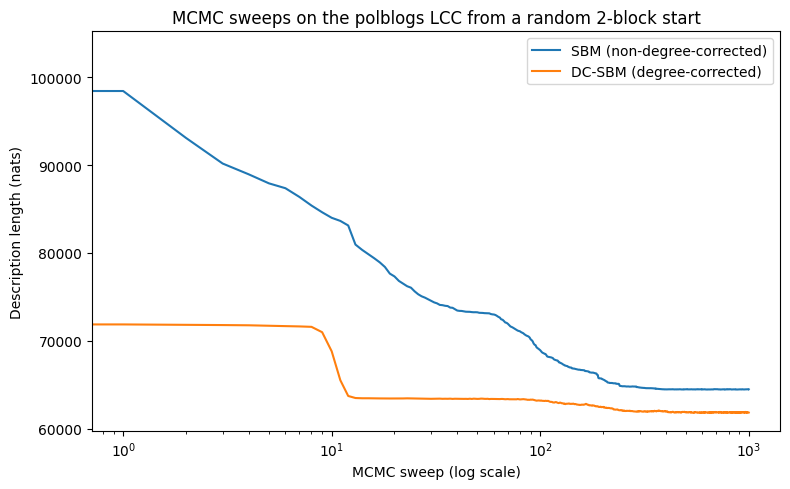

Final description length:  SBM = 64506.3,  DC-SBM = 61860.8
Final number of blocks:    SBM = 16,  DC-SBM = 6
Mean ± std over last 500 sweeps:  SBM = 64493.7 ± 10.2,  DC-SBM = 61874.9 ± 20.7


In [ ]:
n_iter = 1000
gt.seed_rng(42); np.random.seed(42)

# same random 2-block initial partition for both models
b0 = np.random.randint(0, 2, g.num_vertices())

def run_mcmc(g, deg_corr, b0, n_iter):
    state = gt.BlockState(g, b=g.new_vp("int", vals=b0), deg_corr=deg_corr)
    dl = [state.entropy()]                  # description length before any sweep
    B = [len(np.unique(state.get_blocks().a))]
    for _ in range(n_iter):
        state.mcmc_sweep(niter=1)           # one sweep; B is NOT constrained
        dl.append(state.entropy())
        B.append(len(np.unique(state.get_blocks().a)))
    return state, np.array(dl), np.array(B)

mc_sbm, dl_sbm, B_sbm = run_mcmc(g, False, b0, n_iter)
mc_dc,  dl_dc,  B_dc  = run_mcmc(g, True,  b0, n_iter)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(dl_sbm, label="SBM (non-degree-corrected)")
ax.plot(dl_dc,  label="DC-SBM (degree-corrected)")
ax.set_xscale("log")                        # the big drop happens in the first few sweeps
ax.set_xlabel("MCMC sweep (log scale)")
ax.set_ylabel("Description length (nats)")
ax.set_title("MCMC sweeps on the polblogs LCC from a random 2-block start")
ax.legend()
plt.tight_layout(); plt.show()

print(f"Final description length:  SBM = {dl_sbm[-1]:.1f},  DC-SBM = {dl_dc[-1]:.1f}")
print(f"Final number of blocks:    SBM = {B_sbm[-1]},  DC-SBM = {B_dc[-1]}")
print(f"Mean ± std over last 500 sweeps:  "
      f"SBM = {dl_sbm[-500:].mean():.1f} ± {dl_sbm[-500:].std():.1f},  "
      f"DC-SBM = {dl_dc[-500:].mean():.1f} ± {dl_dc[-500:].std():.1f}")